# ReLU Networks: Synthetic Data Experiments

## Objective
Implement the synthetic-data experiments from first principles
to understand feature learning in ReLU networks.


# Stage 1: Synthetic Data Generation (COB-ODT)

## Part 1: Configuration and Setup

We generate synthetic binary classification data using a complete binary decision tree (ODT).

- **Tree depth ($D$):** Number of edges from the root to each leaf.
- **Internal nodes ($M = 2^D - 1$):** Each has a normal vector $u_i$.
- **Leaves ($L = 2^D$):** Each leaf has a label $y \in \{-1, +1\}$.
- **Routing:** Go right if $u_i^T x > 0$, otherwise left.
- **Labels:** Sibling leaves receive opposite labels.

### Dimension Constraint

The normal vectors must be orthonormal, so the input dimension must satisfy:

$$
d \geq 2^D - 1
$$

We choose $d > 2^D - 1$ so that **spurious directions** (directions orthogonal to all tree normals) exist. Studying these directions may help us understand whether ReLU neurons learn meaningful features or grow along unrelated directions.

### Configurations

| Parameter | Debug | Main |
|---|---:|---:|
| Input dimension ($d$) | 20 | 100 |
| Tree depth ($D$) | 4 | 4 |
| Samples ($N$) | 2,000 | 160,000 |

We choose $d = 100$ for the main experiments to provide a sufficiently large orthogonal complement for studying these directions.

We use separate random seeds for tree construction, data sampling, model initialization, and training to ensure reproducibility.


In [1]:
import numpy as np

In [2]:

# Experiment configuration

# Debug configuration
D = 4
d = 20
N = 2000

# Derived quantities
M = 2**D - 1  # Number of internal nodes
L = 2**D      # Number of leaves

# Random seeds
TREE_SEED = 0
DATA_SEED = 42
INIT_SEED = 1
TRAIN_SEED = 100

# Validate the configuration
assert d >= M, "Input dimension must be at least the number of internal nodes."

print(f"Tree depth: {D}")
print(f"Input dimension: {d}")
print(f"Internal nodes: {M}")
print(f"Leaves: {L}")
print(f"Number of samples: {N}")
print(f"Orthogonal complement dimension: {d - M}")


Tree depth: 4
Input dimension: 20
Internal nodes: 15
Leaves: 16
Number of samples: 2000
Orthogonal complement dimension: 5



## Part 2: Sampling Data on the Unit Sphere

We generate $N$ input points in $\mathbb{R}^d$, each uniformly distributed on the unit sphere.

### Sampling Procedure

1. Sample $N$ independent vectors from a multivariate Gaussian distribution:

   $$
   z^{(i)} \sim \mathcal{N}(0, I_d), \qquad i = 1, \ldots, N
   $$

   Here, $I_d$ is the $d \times d$ identity covariance matrix. Equivalently, each vector's components are independent standard normal random variables.

2. Normalize each vector to obtain a unit vector:

   $$
   x^{(i)} = \frac{z^{(i)}}{\|z^{(i)}\|_2}
   $$

Because the Gaussian distribution is rotationally symmetric, each normalized vector is uniformly distributed on the unit sphere.

We generate all $N$ samples together, producing a dataset $X \in \mathbb{R}^{N \times d}$, where each row is one unit vector.

**Validation:** Every row of $X$ should have an $\ell_2$ norm approximately equal to $1$, up to floating-point rounding errors.


In [3]:

def sample_unit_sphere(N, d, seed):
    """Sample N points uniformly from the unit sphere in R^d."""
    rng = np.random.default_rng(seed)

    Z = rng.standard_normal((N, d))
    X = Z / np.linalg.norm(Z, axis=1, keepdims=True)

    return X


In [4]:

X_debug = sample_unit_sphere(N=N, d=d, seed=DATA_SEED)

norms = np.linalg.norm(X_debug, axis=1)

print("Dataset shape:", X_debug.shape)
print("Minimum norm:", norms.min())
print("Maximum norm:", norms.max())

assert X_debug.shape == (N, d)
assert np.allclose(norms, 1.0, atol=1e-12)

print("Validation passed!")


Dataset shape: (2000, 20)
Minimum norm: 0.9999999999999997
Maximum norm: 1.0000000000000002
Validation passed!



## Part 3: Constructing Orthonormal Tree Normals

Each internal node of the decision tree is associated with a normal vector $u_i \in \mathbb{R}^d$.

For a tree of depth $D$, the number of internal nodes is

$$
M = 2^D - 1.
$$

We require the normal vectors to be orthonormal:

$$
u_i^T u_j =
\begin{cases}
1, & i=j,\\
0, & i\ne j.
\end{cases}
$$

We construct these vectors using **QR decomposition**.

Given a random matrix $A \in \mathbb{R}^{d \times M}$ with linearly independent columns, QR decomposition gives

$$
A = QR,
$$

where the columns of $Q \in \mathbb{R}^{d \times M}$ are orthonormal:

$$
Q^TQ = I_M.
$$

We use the columns of $Q$ as the tree normal vectors.


In [5]:

def generate_tree_normals(d, D, seed):
    """Generate orthonormal normal vectors for a complete binary tree."""
    M = 2**D - 1

    assert d >= M, "Dimension must be at least the number of internal nodes."

    rng = np.random.default_rng(seed)
    A = rng.standard_normal((d, M))

    Q, R = np.linalg.qr(A)

    # Store each normal vector as a row
    normals = Q.T

    return normals


In [6]:

U_debug = generate_tree_normals(d=d, D=D, seed=TREE_SEED)

# Check dimensions
print("Normals shape:", U_debug.shape)

# Check that every normal has unit length
normal_norms = np.linalg.norm(U_debug, axis=1)

# Check that distinct normals are orthogonal
gram_matrix = U_debug @ U_debug.T

print("Minimum normal norm:", normal_norms.min())
print("Maximum normal norm:", normal_norms.max())
print(
    "Maximum orthogonality error:",
    np.max(np.abs(gram_matrix - np.eye(M)))
)

assert U_debug.shape == (M, d)
assert np.allclose(normal_norms, 1.0, atol=1e-12)
assert np.allclose(gram_matrix, np.eye(M), atol=1e-12)

print("Validation passed!")


Normals shape: (15, 20)
Minimum normal norm: 0.9999999999999997
Maximum normal norm: 1.0000000000000004
Maximum orthogonality error: 8.881784197001252e-16
Validation passed!



## Part 4: Routing Samples Through the Decision Tree

Each internal node $i$ has a normal vector $u_i \in \mathbb{R}^d$, which defines a decision boundary passing through the origin.

### 1. Compute routing scores

For an input sample $x \in \mathbb{R}^d$, the score at node $i$ is

$$
s_i = u_i^T x.
$$

The sign of the score determines the branch:

$$
\begin{cases}
\text{Right}, & s_i > 0,\\
\text{Left}, & s_i \leq 0.
\end{cases}
$$

We can compute the scores for all samples and all internal nodes using matrix multiplication:

$$
S = XU^T,
$$

where $X \in \mathbb{R}^{N \times d}$ is the sample matrix and $U \in \mathbb{R}^{M \times d}$ contains the tree normals. Thus, $S \in \mathbb{R}^{N \times M}$.

### 2. Represent the tree using heap indexing

We use zero-based indexing to represent the complete binary tree:

- Root node: index $0$.
- Left child of node $i$: index $2i+1$.
- Right child of node $i$: index $2i+2$.

For a tree of depth $D$, the internal nodes have indices $0$ through $2^D-2$, while the leaves have indices $2^D-1$ through $2^{D+1}-2$.

### 3. Route each sample

Starting at the root, we inspect the score at the current node and move to the corresponding child. We repeat this process for exactly $D$ decisions, until the sample reaches a leaf.

If the final tree index is $j$, its leaf ID is

$$
\text{leaf ID} = j - (2^D-1).
$$

This maps the leaf indices to IDs from $0$ through $2^D-1$.

### 4. Tree structure

For a complete binary tree of depth $D$:

- Internal nodes: $M = 2^D-1$.
- Leaves: $L = 2^D$.
- Branch decisions per sample: $D$.

For our debug configuration, $D=4$, giving 15 internal nodes and 16 leaves. Every sample follows a path of four decisions and reaches exactly one leaf.

**Important:** Although scores are computed for all internal nodes, only the scores of the nodes visited along a sample's path determine its leaf.


In [7]:
def route_samples(X, normals, D):
    """Route each sample and record the internal nodes it visits."""

    # Compute scores for every sample and every internal node
    scores = X @ normals.T

    N = X.shape[0]
    M = 2**D - 1

    # Store the leaf reached by each sample
    leaf_ids = np.zeros(N, dtype=int)

    # Record whether each sample visits each internal node
    visited = np.zeros((N, M), dtype=bool)

    # Traverse the tree, making D branch decisions per sample
    for i in range(N):
        node = 0

        for _ in range(D):
            visited[i, node] = True

            go_right = scores[i, node] > 0

            # Heap indexing: left child = 2*node+1,
            # right child = 2*node+2
            if go_right:
                node = 2 * node + 2
            else:
                node = 2 * node + 1

        # Convert the final heap index to a leaf ID
        leaf_ids[i] = node - (2**D - 1)

    return leaf_ids, visited

In [8]:
leaf_ids_debug, visited_debug = route_samples(
    X_debug, U_debug, D
)

print("Leaf IDs shape:", leaf_ids_debug.shape)
print("Visited matrix shape:", visited_debug.shape)
print("Unique leaves reached:", np.unique(leaf_ids_debug))
print("Leaf ID range:", leaf_ids_debug.min(), "to", leaf_ids_debug.max())

# Validate leaf IDs
assert leaf_ids_debug.shape == (N,)
assert np.all((leaf_ids_debug >= 0) & (leaf_ids_debug < L))

# Validate the visited-node matrix
assert visited_debug.shape == (N, M)
assert visited_debug.dtype == bool
assert np.all(visited_debug.sum(axis=1) == D)

print("Routing validation passed!")

Leaf IDs shape: (2000,)
Visited matrix shape: (2000, 15)
Unique leaves reached: [ 0  1  2  3  4  5  6  7  8  9 10 11 12 13 14 15]
Leaf ID range: 0 to 15
Routing validation passed!



## Part 5: Assigning Labels to Leaves

Each leaf of the decision tree is assigned a binary label:

$$
y \in \{-1,+1\}.
$$

The label of a sample is determined by the leaf it reaches during routing.

### Sibling-label constraint

Every pair of sibling leaves must have opposite labels. If leaves $a$ and $b$ are siblings, then

$$
y_a = -y_b.
$$

We first construct a label for every leaf. We then assign each sample the label of its reached leaf:

$$
y^{(i)} = y_{\ell_i},
$$

where $\ell_i$ is the leaf ID of sample $i$.

The resulting dataset consists of the input matrix $X$ and its binary labels $y$.


In [9]:

def generate_leaf_labels(D):
    """Assign alternating binary labels to the leaves."""
    L = 2**D
    leaf_ids = np.arange(L)

    labels = np.where(leaf_ids % 2 == 0, 1, -1)

    return labels


In [10]:

leaf_labels_debug = generate_leaf_labels(D)

# Assign each sample the label of its reached leaf
y_debug = leaf_labels_debug[leaf_ids_debug]

print("Leaf labels:", leaf_labels_debug)
print("Sample labels shape:", y_debug.shape)
print("Unique sample labels:", np.unique(y_debug))

# Check that sibling leaves have opposite labels
assert np.all(leaf_labels_debug[0::2] == -leaf_labels_debug[1::2])

# Check the sample labels
assert y_debug.shape == (N,)
assert set(np.unique(y_debug)).issubset({-1, 1})

print("Label validation passed!")


Leaf labels: [ 1 -1  1 -1  1 -1  1 -1  1 -1  1 -1  1 -1  1 -1]
Sample labels shape: (2000,)
Unique sample labels: [-1  1]
Label validation passed!


## Part 6: Complete Synthetic Dataset Generator

We combine the previously implemented components into a single function:

1. Sample inputs uniformly from the unit sphere.
2. Generate orthonormal decision-boundary normals.
3. Route each input through the tree to determine its leaf.
4. Assign labels to leaves.
5. Assign each sample the label of its reached leaf.

The function returns the generated dataset along with the tree information needed for later experiments.

In [11]:
def generate_cob_odt_data(N, d, D, data_seed, tree_seed):
    """Generate synthetic data using a complete binary decision tree."""

    X = sample_unit_sphere(N=N, d=d, seed=data_seed)

    normals = generate_tree_normals(d=d, D=D, seed=tree_seed)

    leaf_ids, visited = route_samples(
        X=X, normals=normals, D=D
    )

    leaf_labels = generate_leaf_labels(D=D)

    y = leaf_labels[leaf_ids]

    return X, y, normals, leaf_ids, leaf_labels, visited

In [12]:
X_debug, y_debug, U_debug, leaf_ids_debug, leaf_labels_debug, visited_debug = (
    generate_cob_odt_data(
        N=N,
        d=d,
        D=D,
        data_seed=DATA_SEED,
        tree_seed=TREE_SEED
    )
)

print("Input shape:", X_debug.shape)
print("Label shape:", y_debug.shape)
print("Tree normals shape:", U_debug.shape)
print("Leaf IDs shape:", leaf_ids_debug.shape)
print("Leaf labels shape:", leaf_labels_debug.shape)
print("Visited matrix shape:", visited_debug.shape)
print("Nodes visited per sample:", np.unique(visited_debug.sum(axis=1)))
print("Unique sample labels:", np.unique(y_debug))

assert X_debug.shape == (N, d)
assert y_debug.shape == (N,)
assert U_debug.shape == (M, d)
assert leaf_ids_debug.shape == (N,)
assert leaf_labels_debug.shape == (L,)
assert visited_debug.shape == (N, M)
assert visited_debug.dtype == bool

assert np.allclose(np.linalg.norm(X_debug, axis=1), 1.0)
assert np.allclose(U_debug @ U_debug.T, np.eye(M))
assert np.all((leaf_ids_debug >= 0) & (leaf_ids_debug < L))
assert np.all(np.isin(y_debug, [-1, 1]))
assert np.array_equal(y_debug, leaf_labels_debug[leaf_ids_debug])
assert np.all(visited_debug.sum(axis=1) == D)

assert np.all(leaf_labels_debug[0::2] == -leaf_labels_debug[1::2])

print("End-to-end validation passed!")

Input shape: (2000, 20)
Label shape: (2000,)
Tree normals shape: (15, 20)
Leaf IDs shape: (2000,)
Leaf labels shape: (16,)
Visited matrix shape: (2000, 15)
Nodes visited per sample: [4]
Unique sample labels: [-1  1]
End-to-end validation passed!


## Stage 2: ReLU MLP Model

We implement a fully connected neural network with ReLU activations and no biases.

The network takes an input $(x \in \mathbb{R}^d$) and produces one scalar logit:

$$
f_\theta(x) = W_{K+1}\,\sigma\left(
W_K \sigma\left(\cdots \sigma(W_1x)\right)
\right),
$$

where $(\sigma(z)=\max(0,z))$ is the ReLU activation, and all bias terms are omitted.

The architecture will be configurable in terms of the number of hidden layers and their widths. We will validate the forward pass before proceeding to initialization checks.

In [13]:
import torch
import torch.nn as nn
import torch.nn.functional as F

## Step 1: Implement and Validate the Model

We implement the configurable ReLU MLP and verify that it produces one scalar logit per input, contains no bias terms, and has the expected number of parameters.

In [14]:
class ReLUMLP(nn.Module):
    def __init__(self, input_dim, hidden_widths):
        super().__init__()

        layers = []
        current_dim = input_dim

        for width in hidden_widths:
            layers.append(nn.Linear(current_dim, width, bias=False))
            layers.append(nn.ReLU())
            current_dim = width

        layers.append(nn.Linear(current_dim, 1, bias=False))

        self.network = nn.Sequential(*layers)

    def forward(self, x):
        return self.network(x)


def make_model(input_dim, hidden_widths, init_seed):
    torch.manual_seed(init_seed)
    return ReLUMLP(input_dim, hidden_widths)

In [15]:
model = make_model(
    input_dim=d,
    hidden_widths=[40, 40, 40],
    init_seed=INIT_SEED
)

X_batch = torch.tensor(X_debug[:32], dtype=torch.float32)
logits = model(X_batch)

print("Input shape:", X_batch.shape)
print("Output shape:", logits.shape)
print("Number of parameters:", sum(p.numel() for p in model.parameters()))

assert logits.shape == (32, 1)
assert all(
    layer.bias is None
    for layer in model.modules()
    if isinstance(layer, nn.Linear)
)

print("Model architecture validation passed!")

Input shape: torch.Size([32, 20])
Output shape: torch.Size([32, 1])
Number of parameters: 4040
Model architecture validation passed!


### Step 2: Validate Weight Initialization

PyTorch initializes the weights of each `nn.Linear` layer automatically.

For a linear layer with `fan_in = d`, the default weight initialization is uniform:

$$
W_{ij} \sim \mathcal{U}\left(-\frac{1}{\sqrt{d}},\frac{1}{\sqrt{d}}\right).
$$

For a first-layer weight row $(w_j \in \mathbb{R}^d)$, we expect its norm to be approximately

$$
\|w_j\|_2 \approx \frac{1}{\sqrt{3}}.
$$

We will measure the norm of every first-layer weight row and compare the results with this expected value.

In [16]:
# Extract the first linear layer
first_layer = next(
    layer for layer in model.modules()
    if isinstance(layer, nn.Linear)
)

# Get its weight matrix
W1 = first_layer.weight.detach()

# Compute the norm of each row
row_norms = torch.linalg.norm(W1, dim=1)

expected_norm = 1 / np.sqrt(3)

print("First-layer weight shape:", W1.shape)
print("Expected row norm:", expected_norm)
print("Mean row norm:", row_norms.mean().item())
print("Minimum row norm:", row_norms.min().item())
print("Maximum row norm:", row_norms.max().item())

First-layer weight shape: torch.Size([40, 20])
Expected row norm: 0.5773502691896258
Mean row norm: 0.5733323693275452
Minimum row norm: 0.421882688999176
Maximum row norm: 0.6785680651664734


### Step 3: Validate Initial Predictions and Loss

Before training, we check the network's initial predictions and loss.

Since the network produces logits, we use binary cross-entropy with logits (`BCEWithLogitsLoss`).

Our synthetic labels are $(y \in \{-1,+1\})$, whereas binary cross-entropy expects targets in \(\{0,1\}\). We therefore convert the labels using

$$
y_{\text{binary}} = \frac{y+1}{2}.
$$

When the logits are close to zero, the predicted probabilities are close to \(0.5\), and the binary cross-entropy loss is close to

$$
\mathcal{L} \approx \log 2 \approx 0.6931.
$$

We measure the initial logits and loss before any optimization.

In [17]:
X_tensor = torch.tensor(X_debug, dtype=torch.float32)

# Keep labels in {-1, +1} for the research logistic loss
y_binary_sign = torch.tensor(
    y_debug, dtype=torch.float32
).reshape(-1, 1)

logits = model(X_tensor)

# Research logistic loss: log(1 + exp(-y * f(x)))
initial_loss = F.softplus(-y_binary_sign * logits).mean()

print("Mean logit:", logits.mean().item())
print("Minimum logit:", logits.min().item())
print("Maximum logit:", logits.max().item())
print("Initial research logistic loss:", initial_loss.item())

Mean logit: -0.0017556052189320326
Minimum logit: -0.010309331119060516
Maximum logit: 0.010097337886691093
Initial research logistic loss: 0.6931908130645752


### Step 4: Validate Initial Alignment

The synthetic decision tree is defined by a set of unit normals $(u_1,\ldots,u_M)$. The first-layer neurons have weight vectors $(w_1,\ldots,w_m)$.

We measure the cosine similarity between each first-layer weight vector and each tree normal:

$$
\cos(w_j,u_i)=
\frac{w_j^\top u_i}{\|w_j\|_2\|u_i\|_2}.
$$

The absolute cosine similarity measures how closely two vectors align, regardless of their orientation:

$$
a_{ji} = |\cos(w_j,u_i)|.
$$

We compute the maximum absolute cosine similarity for each first-layer neuron across all tree normals. This measures how closely each neuron aligns with its most similar tree normal at initialization.

Since the initial weights are random, we expect these alignments to be relatively small rather than close to \(1\).

In [18]:
# Extract first-layer weights and tree normals
W1 = first_layer.weight.detach()
U = torch.tensor(U_debug, dtype=torch.float32)

# Compute cosine similarities between every neuron and every tree normal
cosine_similarities = F.normalize(W1, dim=1) @ F.normalize(U, dim=1).T

# Take absolute values because either orientation represents the same hyperplane
absolute_cosines = cosine_similarities.abs()

# Find the best-matching tree normal for each neuron
max_alignment_per_neuron = absolute_cosines.max(dim=1).values

print("Cosine similarity matrix shape:", cosine_similarities.shape)
print("Mean maximum absolute cosine:", max_alignment_per_neuron.mean().item())
print("Minimum maximum absolute cosine:", max_alignment_per_neuron.min().item())
print("Maximum maximum absolute cosine:", max_alignment_per_neuron.max().item())

assert cosine_similarities.shape == (40, M)
assert torch.isfinite(cosine_similarities).all()
assert torch.all(absolute_cosines <= 1.0 + 1e-6)
print("Initial alignment validation passed!")

Cosine similarity matrix shape: torch.Size([40, 15])
Mean maximum absolute cosine: 0.47418007254600525
Minimum maximum absolute cosine: 0.352169930934906
Maximum maximum absolute cosine: 0.6464000344276428
Initial alignment validation passed!


## Stage 3: Training Loop and Checkpointing

We train the ReLU MLP on the synthetic dataset generated in Stage 1.

The training process uses minibatch gradient descent with an optimizer to minimize the logistic loss:

$$
\ell(y,f_\theta(x))=\log\left(1+e^{-y f_\theta(x)}\right),
$$

where $y\in\{-1,+1\}$ is the label and $f_\theta(x)$ is the model's scalar output.

This stage has five objectives:

1. **Prepare the training configuration:** Specify the batch size, learning rate, number of epochs, and random seeds.
2. **Implement the training loop:** Compute predictions and loss, backpropagate gradients, and update model parameters.
3. **Track training progress:** Evaluate the full-training-set loss after each epoch.
4. **Checkpoint model parameters:** Save the complete model state at selected epochs to study feature learning.
5. **Validate the training pipeline:** Test overfitting, determinism, and seed separation before scaling up.

We begin with a small debug experiment and will move to the full dataset after validating the training procedure.

In [33]:
# Training configuration
TRAIN_SEED = 100
BATCH_SIZE = 64
LEARNING_RATE = 1e-3
EPOCHS = 20

# Convert the debug dataset to PyTorch tensors
X_train_tensor = torch.tensor(X_debug, dtype=torch.float32)
y_train_tensor = torch.tensor(
    y_debug, dtype=torch.float32
).reshape(-1, 1)

print("Training input shape:", X_train_tensor.shape)
print("Training label shape:", y_train_tensor.shape)
print("Batch size:", BATCH_SIZE)
print("Learning rate:", LEARNING_RATE)
print("Number of epochs:", EPOCHS)
print("Training seed:", TRAIN_SEED)

# Validate shapes and labels
assert X_train_tensor.shape == X_debug.shape
assert y_train_tensor.shape == (len(y_debug), 1)
assert torch.isfinite(X_train_tensor).all()
assert torch.isfinite(y_train_tensor).all()
assert torch.all((y_train_tensor == -1) | (y_train_tensor == 1))

assert BATCH_SIZE > 0
assert LEARNING_RATE > 0
assert EPOCHS > 0

print("Training configuration validation passed!")

Training input shape: torch.Size([2000, 20])
Training label shape: torch.Size([2000, 1])
Batch size: 64
Learning rate: 0.001
Number of epochs: 20
Training seed: 100
Training configuration validation passed!


### Step 2: Implement the Training Loop

For each minibatch, we perform the following operations:

1. Compute the model's logits, $f_\theta(x_i)$.
2. Calculate the mean logistic loss:

   $$\mathcal{L}=\frac{1}{B}\sum_{i=1}^{B}\log\left(1+e^{-y_i f_\theta(x_i)}\right).$$

3. Clear gradients from the previous update using `optimizer.zero_grad()`.
4. Backpropagate the loss using `loss.backward()` to compute gradients.
5. Update the model parameters using `optimizer.step()`.

We repeat this process for every minibatch and every epoch. After each epoch, we evaluate the loss over the complete training dataset and save the model state at selected checkpoints.

In [34]:
def train_model(
    model,
    X,
    y,
    lr,
    batch_size,
    epochs,
    train_seed,
    checkpoint_epochs=None,
):
    if checkpoint_epochs is None:
        checkpoint_epochs = {0, epochs}
    else:
        checkpoint_epochs = set(checkpoint_epochs) | {0, epochs}

    # Independent random generator for minibatch shuffling
    shuffle_generator = torch.Generator().manual_seed(train_seed)

    optimizer = torch.optim.Adam(model.parameters(), lr=lr)

    loss_history = []
    checkpoints = {}

    def save_checkpoint(epoch):
        checkpoints[epoch] = {
            name: tensor.detach().cpu().clone()
            for name, tensor in model.state_dict().items()
        }

    # Save the initial model state
    save_checkpoint(0)

    for epoch in range(1, epochs + 1):
        model.train()

        permutation = torch.randperm(
            X.shape[0],
            generator=shuffle_generator,
        )

        for start in range(0, X.shape[0], batch_size):
            indices = permutation[start:start + batch_size]

            X_batch = X[indices]
            y_batch = y[indices]

            # Forward pass
            logits = model(X_batch)

            # Logistic loss: log(1 + exp(-y * f(x)))
            loss = F.softplus(-y_batch * logits).mean()

            # Backpropagation and parameter update
            optimizer.zero_grad()
            loss.backward()
            optimizer.step()

        # Evaluate loss over the full training set after the epoch
        model.eval()
        with torch.no_grad():
            full_logits = model(X)
            full_loss = F.softplus(-y * full_logits).mean().item()

        loss_history.append(full_loss)

        if epoch in checkpoint_epochs:
            save_checkpoint(epoch)

        print(
            f"Epoch {epoch:02d}/{epochs}, "
            f"Full training loss: {full_loss:.6f}"
        )

    return loss_history, checkpoints


# Create a fresh model with reproducible initialization
model = make_model(
    input_dim=d,
    hidden_widths=[40, 40, 40],
    init_seed=INIT_SEED,
)

# Train using an independent shuffling seed
epoch_losses, model_checkpoints = train_model(
    model=model,
    X=X_train_tensor,
    y=y_train_tensor,
    lr=LEARNING_RATE,
    batch_size=BATCH_SIZE,
    epochs=EPOCHS,
    train_seed=TRAIN_SEED,
    checkpoint_epochs={1, 2, 5, 10},
)

print("Training completed!")
print("Saved checkpoint epochs:", sorted(model_checkpoints.keys()))

assert sorted(model_checkpoints.keys()) == [0, 1, 2, 5, 10, EPOCHS]
assert len(epoch_losses) == EPOCHS

assert all(
    set(checkpoint.keys()) == set(model.state_dict().keys())
    for checkpoint in model_checkpoints.values()
)

print("Training and checkpoint validation passed!")

Epoch 01/20, Full training loss: 0.691941
Epoch 02/20, Full training loss: 0.687274
Epoch 03/20, Full training loss: 0.666812
Epoch 04/20, Full training loss: 0.635292
Epoch 05/20, Full training loss: 0.616282
Epoch 06/20, Full training loss: 0.602715
Epoch 07/20, Full training loss: 0.586155
Epoch 08/20, Full training loss: 0.568315
Epoch 09/20, Full training loss: 0.551837
Epoch 10/20, Full training loss: 0.534906
Epoch 11/20, Full training loss: 0.519863
Epoch 12/20, Full training loss: 0.515698
Epoch 13/20, Full training loss: 0.511167
Epoch 14/20, Full training loss: 0.499599
Epoch 15/20, Full training loss: 0.484014
Epoch 16/20, Full training loss: 0.473970
Epoch 17/20, Full training loss: 0.466992
Epoch 18/20, Full training loss: 0.462486
Epoch 19/20, Full training loss: 0.453137
Epoch 20/20, Full training loss: 0.445975
Training completed!
Saved checkpoint epochs: [0, 1, 2, 5, 10, 20]
Training and checkpoint validation passed!


In [36]:
# Test reproducibility with identical seeds

model_a = make_model(
    input_dim=d,
    hidden_widths=[40, 40, 40],
    init_seed=INIT_SEED,
)

losses_a, checkpoints_a = train_model(
    model=model_a,
    X=X_train_tensor,
    y=y_train_tensor,
    lr=LEARNING_RATE,
    batch_size=BATCH_SIZE,
    epochs=EPOCHS,
    train_seed=TRAIN_SEED,
    checkpoint_epochs={1, 2, 5, 10},
)

model_b = make_model(
    input_dim=d,
    hidden_widths=[40, 40, 40],
    init_seed=INIT_SEED,
)

losses_b, checkpoints_b = train_model(
    model=model_b,
    X=X_train_tensor,
    y=y_train_tensor,
    lr=LEARNING_RATE,
    batch_size=BATCH_SIZE,
    epochs=EPOCHS,
    train_seed=TRAIN_SEED,
    checkpoint_epochs={1, 2, 5, 10},
)

# Compare loss histories and every checkpoint
assert losses_a == losses_b

assert all(
    torch.equal(
        checkpoints_a[epoch][name],
        checkpoints_b[epoch][name],
    )
    for epoch in checkpoints_a
    for name in checkpoints_a[epoch]
)

print("Determinism test passed!")
print("Identical seeds produce identical loss histories and checkpoints.")

Epoch 01/20, Full training loss: 0.691941
Epoch 02/20, Full training loss: 0.687274
Epoch 03/20, Full training loss: 0.666812
Epoch 04/20, Full training loss: 0.635292
Epoch 05/20, Full training loss: 0.616282
Epoch 06/20, Full training loss: 0.602715
Epoch 07/20, Full training loss: 0.586155
Epoch 08/20, Full training loss: 0.568315
Epoch 09/20, Full training loss: 0.551837
Epoch 10/20, Full training loss: 0.534906
Epoch 11/20, Full training loss: 0.519863
Epoch 12/20, Full training loss: 0.515698
Epoch 13/20, Full training loss: 0.511167
Epoch 14/20, Full training loss: 0.499599
Epoch 15/20, Full training loss: 0.484014
Epoch 16/20, Full training loss: 0.473970
Epoch 17/20, Full training loss: 0.466992
Epoch 18/20, Full training loss: 0.462486
Epoch 19/20, Full training loss: 0.453137
Epoch 20/20, Full training loss: 0.445975
Epoch 01/20, Full training loss: 0.691941
Epoch 02/20, Full training loss: 0.687274
Epoch 03/20, Full training loss: 0.666812
Epoch 04/20, Full training loss: 0

### Step 3: Track Training Loss

We record the full-training-set loss after each epoch and visualize it to inspect the optimization process.

A decreasing loss indicates that the model is improving its fit to the training data. The curve also helps us identify plateaus or unstable optimization.

The loss values are computed using the logistic loss:

$$
\mathcal{L}(\theta)
=
\frac{1}{N}\sum_{i=1}^{N}
\log\left(1+e^{-y_i f_\theta(x_i)}\right).
$$

Here, $N$ is the number of training samples, $y_i\in\{-1,+1\}$ is the label, and $f_\theta(x_i)$ is the model's output.

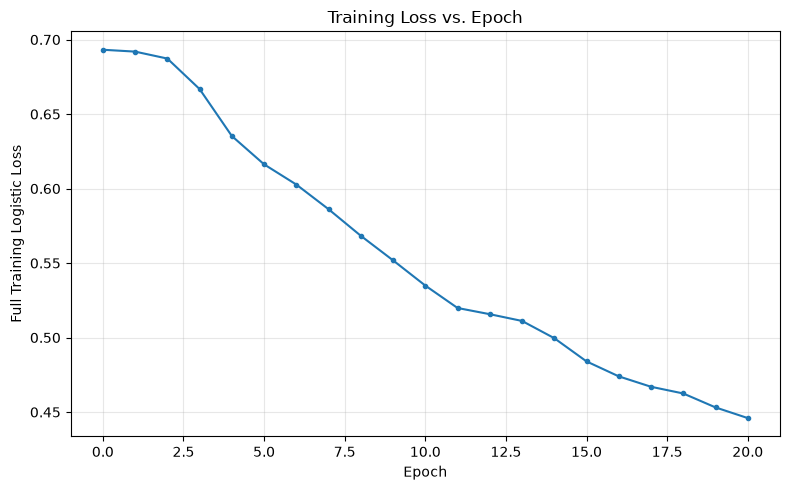

Initial loss (epoch 0): 0.693191
Final loss (epoch 20): 0.445975
Total loss reduction: 0.247216
Training-loss tracking validation passed!


In [37]:
import matplotlib.pyplot as plt

# Epoch 0 is the initial model, before any training.
# model_checkpoints[0] stores its parameters, but epoch_losses starts at epoch 1.
# Evaluate the initial loss so the plot includes the starting point.

initial_model = make_model(
    input_dim=d,
    hidden_widths=[40, 40, 40],
    init_seed=INIT_SEED,
)

initial_logits = initial_model(X_train_tensor)
initial_loss = F.softplus(
    -y_train_tensor * initial_logits
).mean().item()

epochs_axis = list(range(EPOCHS + 1))
loss_values = [initial_loss] + epoch_losses

plt.figure(figsize=(8, 5))
plt.plot(epochs_axis, loss_values, marker="o", markersize=3)
plt.xlabel("Epoch")
plt.ylabel("Full Training Logistic Loss")
plt.title("Training Loss vs. Epoch")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

print(f"Initial loss (epoch 0): {loss_values[0]:.6f}")
print(f"Final loss (epoch {EPOCHS}): {loss_values[-1]:.6f}")
print(f"Total loss reduction: {loss_values[0] - loss_values[-1]:.6f}")

assert len(loss_values) == EPOCHS + 1
assert all(torch.isfinite(torch.tensor(loss)) for loss in loss_values)

print("Training-loss tracking validation passed!")

### Step 4: Checkpoint First-Layer Weights

To study feature learning, we save the model's parameters at initialization and at selected epochs during training.

Let $W_1^{(t)}$ denote the first-layer weight matrix after epoch $t$. We examine the checkpoints

$$
W_1^{(0)}, W_1^{(1)}, W_1^{(2)}, W_1^{(5)},
W_1^{(10)}, W_1^{(20)}.
$$

The first-layer weight matrix contains one weight vector per hidden neuron. By tracking these vectors, we can study how neuron directions change during training and whether they become more aligned with the synthetic decision-tree normals.

The `train_model()` function already saves detached copies of the complete model state at these epochs. We extract the first-layer weights from those saved states for analysis. This ensures that later optimizer updates do not modify earlier checkpoints.

In [22]:
def train_model(
    model,
    X,
    y,
    lr,
    batch_size,
    epochs,
    train_seed,
    checkpoint_epochs=None,
):
    if checkpoint_epochs is None:
        checkpoint_epochs = {0, epochs}
    else:
        checkpoint_epochs = set(checkpoint_epochs) | {0, epochs}

    # Independent random generator for minibatch shuffling
    shuffle_generator = torch.Generator().manual_seed(train_seed)

    optimizer = torch.optim.Adam(model.parameters(), lr=lr)

    loss_history = []
    checkpoints = {}

    def save_checkpoint(epoch):
        checkpoints[epoch] = {
            name: tensor.detach().cpu().clone()
            for name, tensor in model.state_dict().items()
        }

    # Save initial model state
    save_checkpoint(0)

    for epoch in range(1, epochs + 1):
        model.train()

        permutation = torch.randperm(
            X.shape[0],
            generator=shuffle_generator,
        )

        for start in range(0, X.shape[0], batch_size):
            indices = permutation[start:start + batch_size]

            X_batch = X[indices]
            y_batch = y[indices]

            logits = model(X_batch)
            loss = F.softplus(-y_batch * logits).mean()

            optimizer.zero_grad()
            loss.backward()
            optimizer.step()

        # Evaluate loss on the complete training set
        model.eval()
        with torch.no_grad():
            full_logits = model(X)
            full_loss = F.softplus(-y * full_logits).mean().item()

        loss_history.append(full_loss)

        if epoch in checkpoint_epochs:
            save_checkpoint(epoch)

        print(
            f"Epoch {epoch:02d}/{epochs}, "
            f"Full training loss: {full_loss:.6f}"
        )

    return loss_history, checkpoints


# Create a fresh model using the initialization seed
model = make_model(
    input_dim=d,
    hidden_widths=[40, 40, 40],
    init_seed=INIT_SEED,
)

# Train with an independent shuffling seed
epoch_losses, model_checkpoints = train_model(
    model=model,
    X=X_train_tensor,
    y=y_train_tensor,
    lr=LEARNING_RATE,
    batch_size=BATCH_SIZE,
    epochs=EPOCHS,
    train_seed=TRAIN_SEED,
    checkpoint_epochs={1, 2, 5, 10},
)

print("Training completed!")
print("Saved checkpoint epochs:", sorted(model_checkpoints.keys()))

assert sorted(model_checkpoints.keys()) == [0, 1, 2, 5, 10, EPOCHS]
assert len(epoch_losses) == EPOCHS

# Check that each checkpoint contains the complete model state
assert all(
    set(checkpoint.keys()) == set(model.state_dict().keys())
    for checkpoint in model_checkpoints.values()
)

print("Training and checkpoint validation passed!")

Epoch 01/20, Full training loss: 0.691941
Epoch 02/20, Full training loss: 0.687274
Epoch 03/20, Full training loss: 0.666812
Epoch 04/20, Full training loss: 0.635292
Epoch 05/20, Full training loss: 0.616282
Epoch 06/20, Full training loss: 0.602715
Epoch 07/20, Full training loss: 0.586155
Epoch 08/20, Full training loss: 0.568315
Epoch 09/20, Full training loss: 0.551837
Epoch 10/20, Full training loss: 0.534906
Epoch 11/20, Full training loss: 0.519863
Epoch 12/20, Full training loss: 0.515698
Epoch 13/20, Full training loss: 0.511167
Epoch 14/20, Full training loss: 0.499599
Epoch 15/20, Full training loss: 0.484014
Epoch 16/20, Full training loss: 0.473970
Epoch 17/20, Full training loss: 0.466992
Epoch 18/20, Full training loss: 0.462486
Epoch 19/20, Full training loss: 0.453137
Epoch 20/20, Full training loss: 0.445975
Training completed!
Saved checkpoint epochs: [0, 1, 2, 5, 10, 20]
Training and checkpoint validation passed!


### Step 5: Validate Weight Checkpoints

We verify that the first-layer weights are saved correctly and change during training.

For each checkpoint, we measure the Frobenius distance from the initial weight matrix:

$$
\Delta W_1^{(t)}
=
\left\|W_1^{(t)}-W_1^{(0)}\right\|_F.
$$

The Frobenius norm measures the overall magnitude of the changes across all entries of the weight matrix.

At initialization, the distance must be zero. At later checkpoints, a nonzero distance indicates that the first-layer weights have changed.

This validates that the saved checkpoints capture the evolution of the model's weights. Weight changes alone, however, do not establish that the model has learned the underlying features.

In [39]:
# Identify the first linear layer
first_layer_name = next(
    name
    for name, layer in model.named_modules()
    if isinstance(layer, nn.Linear)
)

weight_key = f"{first_layer_name}.weight"

# Extract the initial first-layer weights
W_initial = model_checkpoints[0][weight_key]

# Measure the Frobenius distance at each checkpoint
weight_changes = {}

for epoch in sorted(model_checkpoints.keys()):
    W_current = model_checkpoints[epoch][weight_key]

    distance = torch.linalg.norm(W_current - W_initial).item()
    weight_changes[epoch] = distance

    print(f"Epoch {epoch:02d}: Weight change = {distance:.6f}")

# Validate the initial checkpoint
assert weight_changes[0] == 0.0

# Validate that the final weights differ from initialization
W_final = model_checkpoints[EPOCHS][weight_key]

assert not torch.equal(W_initial, W_final)
assert weight_changes[EPOCHS] > 0.0

# Validate that all recorded distances are finite
assert all(
    torch.isfinite(torch.tensor(distance))
    for distance in weight_changes.values()
)

print("Weight checkpoint validation passed!")

Epoch 00: Weight change = 0.000000
Epoch 01: Weight change = 0.248676
Epoch 02: Weight change = 0.519828
Epoch 05: Weight change = 1.376894
Epoch 10: Weight change = 1.865485
Epoch 20: Weight change = 2.408961
Weight checkpoint validation passed!


### Step 6: Track Feature Alignment

We measure the alignment between each first-layer neuron's weight vector and the synthetic decision-tree normals at each checkpoint.

Let $w_j^{(t)}$ be the weight vector of neuron $j$ at epoch $t$, and let $u_k$ be the normal vector of tree node $k$.

For each neuron, we compute its maximum absolute cosine similarity with any tree normal:

$$
a_j^{(t)}
=
\max_{1\leq k\leq M}
\frac{\left|\langle w_j^{(t)},u_k\rangle\right|}
{\|w_j^{(t)}\|_2\|u_k\|_2}.
$$

We then average this quantity over all $m$ first-layer neurons:

$$
A^{(t)}
=
\frac{1}{m}\sum_{j=1}^{m}a_j^{(t)}.
$$

The absolute value treats parallel and antiparallel vectors as equally aligned.

An increase in $A^{(t)}$ suggests that the first-layer weight directions are becoming more aligned with the tree normals. However, this metric alone does not establish feature learning. We must compare it against a suitable random-alignment baseline and examine the alignment distribution across individual neurons and tree nodes.

In [40]:
# Convert the synthetic tree normals to a tensor
U_tensor = torch.tensor(U_debug, dtype=torch.float32)
U_normalized = F.normalize(U_tensor, p=2, dim=1)

# Identify the first linear layer's weight key
first_layer_name = next(
    name
    for name, layer in model.named_modules()
    if isinstance(layer, nn.Linear)
)
weight_key = f"{first_layer_name}.weight"

alignment_results = {}

for epoch in sorted(model_checkpoints.keys()):
    # Extract first-layer weights from the checkpoint
    W = model_checkpoints[epoch][weight_key]

    # Normalize each neuron's weight vector
    W_normalized = F.normalize(W, p=2, dim=1)

    # Compute cosine similarities: (neurons, tree normals)
    cosine_matrix = W_normalized @ U_normalized.T

    # Maximum absolute cosine similarity for each neuron
    best_alignment = cosine_matrix.abs().max(dim=1).values

    # Average across all first-layer neurons
    mean_alignment = best_alignment.mean().item()
    alignment_results[epoch] = mean_alignment

    print(
        f"Epoch {epoch:02d}: "
        f"Mean maximum alignment = {mean_alignment:.4f}"
    )

# Validate dimensions and values
assert cosine_matrix.shape == (W.shape[0], U_tensor.shape[0])
assert len(alignment_results) == len(model_checkpoints)
assert all(np.isfinite(value) for value in alignment_results.values())
assert all(0.0 <= value <= 1.0 for value in alignment_results.values())

print("Feature-alignment measurement completed!")

Epoch 00: Mean maximum alignment = 0.4742
Epoch 01: Mean maximum alignment = 0.4779
Epoch 02: Mean maximum alignment = 0.4829
Epoch 05: Mean maximum alignment = 0.4880
Epoch 10: Mean maximum alignment = 0.4774
Epoch 20: Mean maximum alignment = 0.4792
Feature-alignment measurement completed!


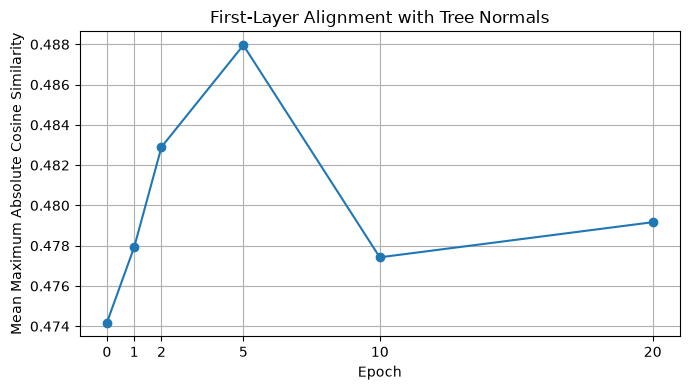

In [42]:
plt.figure(figsize=(7, 4))

epochs = sorted(alignment_results.keys())
alignments = [alignment_results[e] for e in epochs]

plt.plot(epochs, alignments, marker="o")
plt.xlabel("Epoch")
plt.ylabel("Mean Maximum Absolute Cosine Similarity")
plt.title("First-Layer Alignment with Tree Normals")
plt.xticks(epochs)
plt.grid(True)
plt.tight_layout()
plt.show()

### Step 7: Establish a Random-Alignment Baseline

A neuron can have a high maximum cosine similarity with the tree normals purely by chance, especially when we compare it against multiple normals and select the maximum.

To quantify this effect, we generate random unit vectors in the same input dimension as the model and measure their mean maximum absolute cosine similarity with the tree normals.

For each random direction $v$, we compute

$$
a(v)=\max_{1\leq k\leq M}
\frac{|\langle v,u_k\rangle|}
{\|v\|_2\|u_k\|_2}.
$$

We average this quantity over 1,000 random directions to obtain the random-alignment baseline.

We compare this baseline with the alignment at initialization and after training. This helps us determine whether the observed alignment exceeds what can be explained by random directions alone. It does not, by itself, establish that feature learning has occurred.

In [43]:
# Use a separate random generator for reproducibility
baseline_generator = torch.Generator().manual_seed(2026)

NUM_RANDOM_TRIALS = 1000

# Ensure all tree normals are unit vectors
U_normalized = F.normalize(U_tensor, p=2, dim=1)

# Generate random directions in the same input dimension
random_directions = torch.randn(
    NUM_RANDOM_TRIALS,
    d,
    generator=baseline_generator,
)

random_directions = F.normalize(random_directions, p=2, dim=1)

# Compare each random direction against every tree normal
random_cosines = random_directions @ U_normalized.T

# Maximum absolute alignment for each random direction
random_best_alignment = random_cosines.abs().max(dim=1).values

random_baseline = random_best_alignment.mean().item()
initial_alignment = alignment_results[0]
final_alignment = alignment_results[EPOCHS]

print(f"Random-alignment baseline: {random_baseline:.4f}")
print(f"Initial trained-model alignment: {initial_alignment:.4f}")
print(f"Final trained-model alignment: {final_alignment:.4f}")
print(
    f"Change during training: "
    f"{final_alignment - initial_alignment:+.4f}"
)
print(
    f"Final alignment minus random baseline: "
    f"{final_alignment - random_baseline:+.4f}"
)

# Sanity checks
assert random_cosines.shape == (NUM_RANDOM_TRIALS, U_tensor.shape[0])
assert torch.isfinite(random_best_alignment).all()
assert 0.0 <= random_baseline <= 1.0

print("Random-alignment baseline validation passed!")

Random-alignment baseline: 0.4675
Initial trained-model alignment: 0.4742
Final trained-model alignment: 0.4792
Change during training: +0.0050
Final alignment minus random baseline: +0.0117
Random-alignment baseline validation passed!


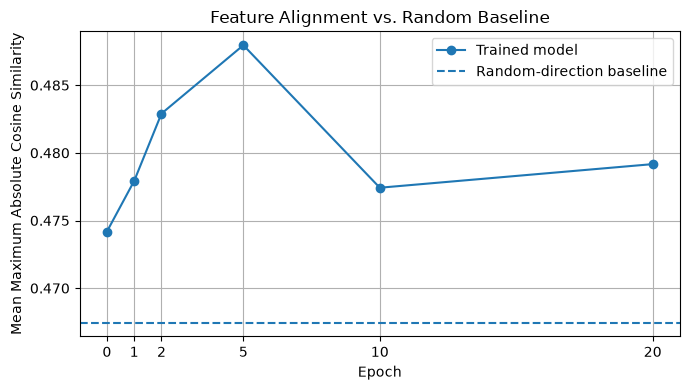

In [46]:
plt.figure(figsize=(7, 4))

epochs = sorted(alignment_results.keys())
alignments = [alignment_results[e] for e in epochs]

plt.plot(
    epochs,
    alignments,
    marker="o",
    label="Trained model"
)

plt.axhline(
    y=random_baseline,
    linestyle="--",
    label="Random-direction baseline"
)

plt.xlabel("Epoch")
plt.ylabel("Mean Maximum Absolute Cosine Similarity")
plt.title("Feature Alignment vs. Random Baseline")
plt.xticks(epochs)
plt.grid(True)
plt.legend()
plt.tight_layout()
plt.show()

## Stage 4: Main Dataset and Generalization Evaluation

The debug experiment validated the training loop, checkpointing, and feature-alignment measurements.

We now prepare the larger synthetic dataset for the main experiments and split it into training, validation, and test sets.

- **Training set:** Used to optimize model parameters.
- **Validation set:** Used to compare configurations and make experimental decisions.
- **Test set:** Reserved for final evaluation and not used for model selection.

We will evaluate both logistic loss and classification accuracy. Feature alignment will remain a separate diagnostic for studying whether first-layer weight directions align with the synthetic decision-tree normals.

All data splits will be created at the sample level, with the same underlying synthetic data-generation process.

### Step 1: Generate the Main Synthetic Dataset

We generate the main dataset using the same synthetic decision-tree mechanism validated in Stage 1, with a higher input dimension and more samples.

We use $d=100$ input dimensions and $N=160{,}000$ samples. The tree depth and alternating leaf-label convention remain unchanged.

We use fixed tree and data seeds to make the dataset generation reproducible.

In [32]:
d_main = 100
N_main = 160_000
DATA_SEED_MAIN = 42

(
    X_main,
    y_main,
    U_main,
    leaf_ids_main,
    leaf_labels_main,
    visited_main,
) = generate_cob_odt_data(
    N=N_main,
    d=d_main,
    D=D,
    tree_seed=TREE_SEED,
    data_seed=DATA_SEED_MAIN,
)

print("Input shape:", X_main.shape)
print("Label shape:", y_main.shape)
print("Tree-normal shape:", U_main.shape)
print("Visited-path shape:", visited_main.shape)
print("Unique labels:", np.unique(y_main))
print("Number of leaves reached:", len(np.unique(leaf_ids_main)))

assert X_main.shape == (N_main, d_main)
assert y_main.shape == (N_main,)
assert U_main.shape == (M, d_main)
assert visited_main.shape == (N_main, M)
assert set(np.unique(y_main)) == {-1, 1}

print("Main dataset validation passed!")

Input shape: (160000, 100)
Label shape: (160000,)
Tree-normal shape: (15, 100)
Visited-path shape: (160000, 15)
Unique labels: [-1  1]
Number of leaves reached: 16
Main dataset validation passed!


### Step 2: Split the Dataset into Training, Validation, and Test Sets

We split the main dataset into three disjoint subsets:

- **Training set (80%):** Used to optimize model parameters.
- **Validation set (10%):** Used to compare configurations and make experimental decisions.
- **Test set (10%):** Reserved for final evaluation.

We use a fixed split seed to make the partition reproducible. The same sample indices are used to partition the inputs and their corresponding labels, ensuring that each input remains paired with its correct label.

We also verify that the subsets are disjoint, cover the complete dataset, and preserve the expected input and label shapes.

In [48]:
# Split configuration
SPLIT_SEED = 123

# Generate a reproducible permutation of all sample indices
rng = np.random.default_rng(SPLIT_SEED)
all_indices = rng.permutation(N_main)

# Split indices: 80% training, 10% validation, 10% test
train_end = int(0.80 * N_main)
val_end = int(0.90 * N_main)

train_indices = all_indices[:train_end]
val_indices = all_indices[train_end:val_end]
test_indices = all_indices[val_end:]

# Create the datasets using the same indices for inputs and labels
X_train_main = X_main[train_indices]
y_train_main = y_main[train_indices]

X_val_main = X_main[val_indices]
y_val_main = y_main[val_indices]

X_test_main = X_main[test_indices]
y_test_main = y_main[test_indices]

# Report split sizes
print("Training set:", X_train_main.shape, y_train_main.shape)
print("Validation set:", X_val_main.shape, y_val_main.shape)
print("Test set:", X_test_main.shape, y_test_main.shape)

# Validate expected sizes
assert len(train_indices) == 128_000
assert len(val_indices) == 16_000
assert len(test_indices) == 16_000

# Verify that the splits are disjoint
assert len(set(train_indices) & set(val_indices)) == 0
assert len(set(train_indices) & set(test_indices)) == 0
assert len(set(val_indices) & set(test_indices)) == 0

# Verify that every sample appears exactly once
combined_indices = np.concatenate(
    [train_indices, val_indices, test_indices]
)
assert len(np.unique(combined_indices)) == N_main
assert np.array_equal(np.sort(combined_indices), np.arange(N_main))

# Validate input and label shapes
assert X_train_main.shape == (128_000, d_main)
assert y_train_main.shape == (128_000,)
assert X_val_main.shape == (16_000, d_main)
assert y_val_main.shape == (16_000,)
assert X_test_main.shape == (16_000, d_main)
assert y_test_main.shape == (16_000,)

print("Dataset split validation passed!")

Training set: (128000, 100) (128000,)
Validation set: (16000, 100) (16000,)
Test set: (16000, 100) (16000,)
Dataset split validation passed!


### Step 3: Convert the Dataset Splits to PyTorch Tensors

We convert the training, validation, and test sets into PyTorch tensors so they can be used by the model.

Inputs and labels are stored as 32-bit floating-point tensors. Labels remain in $\{-1,+1\}$ to match the logistic loss used in Stage 3.

We validate tensor shapes, data types, and label values before training.

In [49]:
# Convert inputs and labels to PyTorch tensors
X_train_tensor = torch.tensor(X_train_main, dtype=torch.float32)
y_train_tensor = torch.tensor(y_train_main, dtype=torch.float32).reshape(-1, 1)

X_val_tensor = torch.tensor(X_val_main, dtype=torch.float32)
y_val_tensor = torch.tensor(y_val_main, dtype=torch.float32).reshape(-1, 1)

X_test_tensor = torch.tensor(X_test_main, dtype=torch.float32)
y_test_tensor = torch.tensor(y_test_main, dtype=torch.float32).reshape(-1, 1)

# Report shapes and data types
for name, tensor in [
    ("X_train_tensor", X_train_tensor),
    ("y_train_tensor", y_train_tensor),
    ("X_val_tensor", X_val_tensor),
    ("y_val_tensor", y_val_tensor),
    ("X_test_tensor", X_test_tensor),
    ("y_test_tensor", y_test_tensor),
]:
    print(f"{name}: shape={tuple(tensor.shape)}, dtype={tensor.dtype}")

# Validate shapes
assert X_train_tensor.shape == (128_000, d_main)
assert y_train_tensor.shape == (128_000, 1)
assert X_val_tensor.shape == (16_000, d_main)
assert y_val_tensor.shape == (16_000, 1)
assert X_test_tensor.shape == (16_000, d_main)
assert y_test_tensor.shape == (16_000, 1)

# Validate data types, finite values, and labels
assert all(
    tensor.dtype == torch.float32
    for tensor in [
        X_train_tensor, y_train_tensor,
        X_val_tensor, y_val_tensor,
        X_test_tensor, y_test_tensor,
    ]
)

assert all(
    torch.isfinite(tensor).all()
    for tensor in [
        X_train_tensor, y_train_tensor,
        X_val_tensor, y_val_tensor,
        X_test_tensor, y_test_tensor,
    ]
)

for labels in [y_train_tensor, y_val_tensor, y_test_tensor]:
    assert torch.all((labels == -1) | (labels == 1))

print("PyTorch tensor validation passed!")

X_train_tensor: shape=(128000, 100), dtype=torch.float32
y_train_tensor: shape=(128000, 1), dtype=torch.float32
X_val_tensor: shape=(16000, 100), dtype=torch.float32
y_val_tensor: shape=(16000, 1), dtype=torch.float32
X_test_tensor: shape=(16000, 100), dtype=torch.float32
y_test_tensor: shape=(16000, 1), dtype=torch.float32
PyTorch tensor validation passed!


### Step 4: Configure the Main Training Experiment

We configure the ReLU MLP for the main dataset. We initially retain the architecture and optimization settings used in the debug experiment so that the larger experiment changes the dataset scale and input dimension without introducing unnecessary changes to the training procedure.

We use the validation set to monitor generalization and select configurations. The test set remains reserved for final evaluation.

The model is initialized independently using the initialization seed, while minibatch shuffling uses a separate training seed.

In [56]:
# Main experiment configuration
MAIN_INIT_SEED = 1
MAIN_TRAIN_SEED = 100

MAIN_HIDDEN_WIDTHS = [40, 40, 40]
MAIN_BATCH_SIZE = 64
MAIN_LEARNING_RATE = 1e-3
MAIN_EPOCHS = 200

print("Input dimension:", d_main)
print("Hidden widths:", MAIN_HIDDEN_WIDTHS)
print("Training samples:", len(X_train_tensor))
print("Batch size:", MAIN_BATCH_SIZE)
print("Learning rate:", MAIN_LEARNING_RATE)
print("Epochs:", MAIN_EPOCHS)
print("Initialization seed:", MAIN_INIT_SEED)
print("Training seed:", MAIN_TRAIN_SEED)

# Validate the configuration
assert d_main == 100
assert MAIN_HIDDEN_WIDTHS == [40, 40, 40]
assert MAIN_BATCH_SIZE > 0
assert MAIN_LEARNING_RATE > 0
assert MAIN_EPOCHS > 0
assert MAIN_INIT_SEED != MAIN_TRAIN_SEED

print("Main training configuration validation passed!")

Input dimension: 100
Hidden widths: [40, 40, 40]
Training samples: 128000
Batch size: 64
Learning rate: 0.001
Epochs: 200
Initialization seed: 1
Training seed: 100
Main training configuration validation passed!


### Step 5: Train the Model and Monitor Generalization

We train the ReLU MLP using minibatches and the logistic loss:

$$
\mathcal{L}(\theta)
=
\frac{1}{N}\sum_{i=1}^{N}
\log\left(1+e^{-y_i f_\theta(x_i)}\right).
$$

After every epoch, we evaluate the loss on both the training and validation sets. We save model checkpoints at selected epochs to support subsequent feature-alignment analysis.

The validation set is used for monitoring and experimental decisions. The test set is not used during training or model selection.

In [57]:
def train_model_with_validation(
    model,
    X_train,
    y_train,
    X_val,
    y_val,
    lr,
    batch_size,
    epochs,
    train_seed,
    checkpoint_epochs=None,
):
    if checkpoint_epochs is None:
        checkpoint_epochs = {0, epochs}
    else:
        checkpoint_epochs = set(checkpoint_epochs) | {0, epochs}

    shuffle_generator = torch.Generator().manual_seed(train_seed)
    optimizer = torch.optim.Adam(model.parameters(), lr=lr)

    train_loss_history = []
    val_loss_history = []
    checkpoints = {}

    def evaluate_loss(X, y):
        model.eval()
        with torch.no_grad():
            logits = model(X)
            return F.softplus(-y * logits).mean().item()

    def save_checkpoint(epoch):
        checkpoints[epoch] = {
            name: tensor.detach().cpu().clone()
            for name, tensor in model.state_dict().items()
        }

    # Record the initial model and its losses
    save_checkpoint(0)
    train_loss_history.append(evaluate_loss(X_train, y_train))
    val_loss_history.append(evaluate_loss(X_val, y_val))

    print(
        f"Epoch 00/{epochs}, "
        f"Train loss: {train_loss_history[-1]:.6f}, "
        f"Validation loss: {val_loss_history[-1]:.6f}"
    )

    for epoch in range(1, epochs + 1):
        model.train()

        permutation = torch.randperm(
            X_train.shape[0],
            generator=shuffle_generator,
        )

        for start in range(0, X_train.shape[0], batch_size):
            indices = permutation[start:start + batch_size]
            X_batch = X_train[indices]
            y_batch = y_train[indices]

            logits = model(X_batch)
            loss = F.softplus(-y_batch * logits).mean()

            optimizer.zero_grad()
            loss.backward()
            optimizer.step()

        # Evaluate after each epoch
        train_loss = evaluate_loss(X_train, y_train)
        val_loss = evaluate_loss(X_val, y_val)

        train_loss_history.append(train_loss)
        val_loss_history.append(val_loss)

        if epoch in checkpoint_epochs:
            save_checkpoint(epoch)

        print(
            f"Epoch {epoch:02d}/{epochs}, "
            f"Train loss: {train_loss:.6f}, "
            f"Validation loss: {val_loss:.6f}"
        )

    return train_loss_history, val_loss_history, checkpoints


print("Validation-aware training function defined.")


Validation-aware training function defined.


In [58]:
# Create a fresh model for the main experiment
main_model = make_model(
    input_dim=d_main,
    hidden_widths=MAIN_HIDDEN_WIDTHS,
    init_seed=MAIN_INIT_SEED,
)

# Train while monitoring training and validation loss
(
    main_train_losses,
    main_val_losses,
    main_model_checkpoints,
) = train_model_with_validation(
    model=main_model,
    X_train=X_train_tensor,
    y_train=y_train_tensor,
    X_val=X_val_tensor,
    y_val=y_val_tensor,
    lr=MAIN_LEARNING_RATE,
    batch_size=MAIN_BATCH_SIZE,
    epochs=MAIN_EPOCHS,
    train_seed=MAIN_TRAIN_SEED,
    checkpoint_epochs={1, 2, 5, 10},
)

print("Main training completed!")
print("Training-loss measurements:", len(main_train_losses))
print("Validation-loss measurements:", len(main_val_losses))
print("Saved checkpoint epochs:", sorted(main_model_checkpoints.keys()))

# Validate training histories and checkpoints
assert len(main_train_losses) == MAIN_EPOCHS + 1
assert len(main_val_losses) == MAIN_EPOCHS + 1
assert sorted(main_model_checkpoints.keys()) == [0, 1, 2, 5, 10, MAIN_EPOCHS]

assert all(np.isfinite(loss) for loss in main_train_losses)
assert all(np.isfinite(loss) for loss in main_val_losses)

print("Main training validation passed!")

Epoch 00/200, Train loss: 0.693151, Validation loss: 0.693134
Epoch 01/200, Train loss: 0.586462, Validation loss: 0.602029
Epoch 02/200, Train loss: 0.514610, Validation loss: 0.533697
Epoch 03/200, Train loss: 0.469049, Validation loss: 0.491528
Epoch 04/200, Train loss: 0.433066, Validation loss: 0.457124
Epoch 05/200, Train loss: 0.394820, Validation loss: 0.415012
Epoch 06/200, Train loss: 0.348738, Validation loss: 0.368255
Epoch 07/200, Train loss: 0.315488, Validation loss: 0.334772
Epoch 08/200, Train loss: 0.286501, Validation loss: 0.307780
Epoch 09/200, Train loss: 0.267333, Validation loss: 0.289732
Epoch 10/200, Train loss: 0.251999, Validation loss: 0.275286
Epoch 11/200, Train loss: 0.248684, Validation loss: 0.273745
Epoch 12/200, Train loss: 0.231275, Validation loss: 0.253722
Epoch 13/200, Train loss: 0.217776, Validation loss: 0.238617
Epoch 14/200, Train loss: 0.215766, Validation loss: 0.241138
Epoch 15/200, Train loss: 0.220029, Validation loss: 0.248111
Epoch 16

In [60]:
def evaluate_accuracy(model, X, y, batch_size=4096):
    model.eval()
    correct = 0
    total = 0

    with torch.no_grad():
        for start in range(0, len(X), batch_size):
            X_batch = X[start:start + batch_size]
            y_batch = y[start:start + batch_size]

            logits = model(X_batch)
            predictions = torch.where(
                logits >= 0,
                1.0,
                -1.0,
            )

            correct += (predictions == y_batch).sum().item()
            total += y_batch.numel()

    return correct / total

In [61]:
train_accuracy = evaluate_accuracy(
    main_model, X_train_tensor, y_train_tensor
)

val_accuracy = evaluate_accuracy(
    main_model, X_val_tensor, y_val_tensor
)

print(f"Training accuracy:   {100 * train_accuracy:.2f}%")
print(f"Validation accuracy: {100 * val_accuracy:.2f}%")

Training accuracy:   99.03%
Validation accuracy: 97.07%


In [62]:
test_accuracy = evaluate_accuracy(
    main_model,
    X_test_tensor,
    y_test_tensor,
)

print(f"Test accuracy: {100 * test_accuracy:.2f}%")

Test accuracy: 96.86%


In [63]:
def compute_feature_alignment(model, tree_normals):
    # First linear layer: shape (hidden_width, input_dim)
    W = model.network[0].weight.detach().cpu()

    # Ground-truth tree normals: shape (num_tree_nodes, input_dim)
    U = torch.as_tensor(tree_normals, dtype=W.dtype)

    # Normalize each neuron weight and each tree normal.
    W_norm = W / W.norm(dim=1, keepdim=True).clamp_min(1e-12)
    U_norm = U / U.norm(dim=1, keepdim=True).clamp_min(1e-12)

    # Absolute cosine similarity between every neuron and every tree normal.
    cosine_similarities = torch.abs(W_norm @ U_norm.T)

    # Best-matching tree normal for each neuron, averaged over neurons.
    alignment = cosine_similarities.max(dim=1).values.mean().item()

    return alignment


alignment_results = {}

for epoch, state_dict in main_model_checkpoints.items():
    checkpoint_model = make_model(
        input_dim=d_main,
        hidden_widths=MAIN_HIDDEN_WIDTHS,
        init_seed=MAIN_INIT_SEED,
    )
    checkpoint_model.load_state_dict(state_dict)

    alignment_results[epoch] = compute_feature_alignment(
        checkpoint_model,
        U_main,
    )

print("Feature alignment by checkpoint:")
for epoch, alignment in alignment_results.items():
    print(f"Epoch {epoch:3d}: {alignment:.4f}")

Feature alignment by checkpoint:
Epoch   0: 0.2127
Epoch   1: 0.4662
Epoch   2: 0.5742
Epoch   5: 0.7315
Epoch  10: 0.8520
Epoch 200: 0.8930


In [64]:
def random_direction_alignment(
    tree_normals,
    input_dim,
    num_directions=10_000,
    seed=2026,
):
    rng = np.random.default_rng(seed)

    random_directions = rng.standard_normal(
        size=(num_directions, input_dim)
    )
    random_directions /= np.linalg.norm(
        random_directions, axis=1, keepdims=True
    )

    U = np.asarray(tree_normals)
    U = U / np.linalg.norm(U, axis=1, keepdims=True)

    cosine_similarities = np.abs(random_directions @ U.T)
    best_matches = cosine_similarities.max(axis=1)

    return best_matches.mean(), best_matches.std()


random_mean, random_std = random_direction_alignment(
    tree_normals=U_main,
    input_dim=d_main,
    num_directions=10_000,
    seed=2026,
)

initial_alignment = alignment_results[0]
final_alignment = alignment_results[200]

print(f"Random-direction baseline: {random_mean:.4f} ± {random_std:.4f}")
print(f"Initial alignment:         {initial_alignment:.4f}")
print(f"Final alignment:           {final_alignment:.4f}")
print(f"Alignment increase:        {final_alignment - initial_alignment:+.4f}")
print(f"Final minus baseline:      {final_alignment - random_mean:+.4f}")

Random-direction baseline: 0.2061 ± 0.0468
Initial alignment:         0.2127
Final alignment:           0.8930
Alignment increase:        +0.6803
Final minus baseline:      +0.6869


In [65]:
def get_neuron_alignment_scores(model, tree_normals):
    W = model.network[0].weight.detach().cpu()
    U = torch.as_tensor(tree_normals, dtype=W.dtype)

    W_norm = W / W.norm(dim=1, keepdim=True).clamp_min(1e-12)
    U_norm = U / U.norm(dim=1, keepdim=True).clamp_min(1e-12)

    similarities = torch.abs(W_norm @ U_norm.T)
    best_scores, best_nodes = similarities.max(dim=1)

    return best_scores.numpy(), best_nodes.numpy()


final_neuron_scores, final_best_nodes = get_neuron_alignment_scores(
    main_model,
    U_main,
)

print("Number of first-layer neurons:", len(final_neuron_scores))
print(f"Mean alignment:   {final_neuron_scores.mean():.4f}")
print(f"Median alignment: {np.median(final_neuron_scores):.4f}")
print(f"Minimum alignment:{final_neuron_scores.min():.4f}")
print(f"Maximum alignment:{final_neuron_scores.max():.4f}")

for threshold in [0.5, 0.7, 0.9, 0.95]:
    count = np.sum(final_neuron_scores >= threshold)
    print(
        f"Neurons with alignment >= {threshold:.2f}: "
        f"{count}/{len(final_neuron_scores)} "
        f"({100 * count / len(final_neuron_scores):.1f}%)"
    )

Number of first-layer neurons: 40
Mean alignment:   0.8930
Median alignment: 0.9786
Minimum alignment:0.3908
Maximum alignment:0.9978
Neurons with alignment >= 0.50: 38/40 (95.0%)
Neurons with alignment >= 0.70: 35/40 (87.5%)
Neurons with alignment >= 0.90: 28/40 (70.0%)
Neurons with alignment >= 0.95: 25/40 (62.5%)


In [66]:
node_counts = np.bincount(
    final_best_nodes,
    minlength=M,
)

print("Neuron assignments to ground-truth tree nodes:")
for node_id, count in enumerate(node_counts):
    print(f"Node {node_id:2d}: {count:2d} neurons")

print()
print("Number of tree nodes matched by at least one neuron:",
      np.sum(node_counts > 0))
print("Number of unmatched tree nodes:",
      np.sum(node_counts == 0))
print("Maximum neurons assigned to one node:",
      node_counts.max())

Neuron assignments to ground-truth tree nodes:
Node  0:  9 neurons
Node  1:  4 neurons
Node  2:  4 neurons
Node  3:  3 neurons
Node  4:  2 neurons
Node  5:  3 neurons
Node  6:  3 neurons
Node  7:  2 neurons
Node  8:  2 neurons
Node  9:  2 neurons
Node 10:  1 neurons
Node 11:  2 neurons
Node 12:  1 neurons
Node 13:  1 neurons
Node 14:  1 neurons

Number of tree nodes matched by at least one neuron: 15
Number of unmatched tree nodes: 0
Maximum neurons assigned to one node: 9


In [67]:
depth_counts = {
    0: (0, 1),
    1: (1, 3),
    2: (3, 7),
    3: (7, 15),
}

print("Neuron assignments by tree depth:")

for depth, (start_node, end_node) in depth_counts.items():
    count = int(node_counts[start_node:end_node].sum())
    num_nodes = end_node - start_node

    print(
        f"Depth {depth}: {count:2d} neurons assigned "
        f"across {num_nodes} nodes "
        f"({count / len(final_best_nodes):.1%} of neurons)"
    )

Neuron assignments by tree depth:
Depth 0:  9 neurons assigned across 1 nodes (22.5% of neurons)
Depth 1:  8 neurons assigned across 2 nodes (20.0% of neurons)
Depth 2: 11 neurons assigned across 4 nodes (27.5% of neurons)
Depth 3: 12 neurons assigned across 8 nodes (30.0% of neurons)


In [68]:
print("Alignment strength by tree depth:")

for depth, (start_node, end_node) in depth_counts.items():
    neuron_mask = (
        (final_best_nodes >= start_node)
        & (final_best_nodes < end_node)
    )
    scores = final_neuron_scores[neuron_mask]

    print(
        f"Depth {depth}: "
        f"neurons={len(scores):2d}, "
        f"mean alignment={scores.mean():.4f}, "
        f"median alignment={np.median(scores):.4f}"
    )

Alignment strength by tree depth:
Depth 0: neurons= 9, mean alignment=0.9292, median alignment=0.9942
Depth 1: neurons= 8, mean alignment=0.9037, median alignment=0.9900
Depth 2: neurons=11, mean alignment=0.8636, median alignment=0.9810
Depth 3: neurons=12, mean alignment=0.8857, median alignment=0.9501
